# Анализ случайной величины cal_refractivity

In [ ]:
from pathlib import Path
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

RNG = np.random.default_rng(42)

url = "https://raw.githubusercontent.com/Cbl41K/StatsLab1/refs/heads/main/cleaned_data.csv"
df = pd.read_csv(url)
x = df["cal_refractivity"].dropna().to_numpy()
N = len(df)
print(f"Объем генеральной совокупности (молекул): {N}, пропусков в cal_refractivity: {df['cal_refractivity'].isna().sum()}")

Объем генеральной совокупности (молекул): 10046, пропусков в cal_refractivity: 0


## 1. почему cal_refractivity — случайная величина

Молекулярная рефракция это физико-химическая характеристика, показывает электронную поляризуемость вещества и его молекулярный объём. При случайном извлечении химического соединения из базы данных мы заранее не можем предсказать точное значение этого параметра из-за структурного разнообразия молекул

### математическое обоснование вероятностной природы
Необходимо убедиться, что исследуемый признак подчиняется законам теории вероятностей. Для этого эмпирически проверяются три фундаментальные теоремы:
1. **Закон больших чисел:** Утверждает, что выборочное среднее при увеличении объёма выборки $n$ сходится по вероятности к мат.ожиданию генеральной совокупности
2. **Центральная предельная теорема:** Устанавливает, что распределение выборочных средних при достаточно большом $n$ стремится к нормальному закону $\mathcal{N}(0, 1)$ независимо от формы исходного распределения признака
3. **Теорема Гливенко — Кантелли:** Гарантирует равномерную сходимость эмпирической функции распределения к истинной генеральной функции распределения

Ниже приведена общая гистограмма плотности вероятности по всей генеральной совокупности

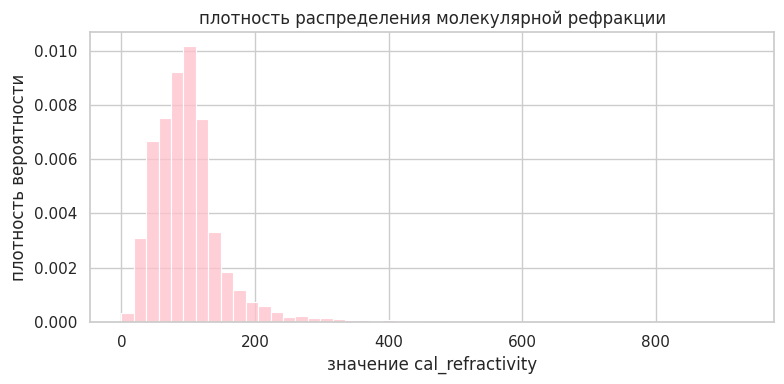

In [ ]:
fig, axes = plt.subplots(1, 1, figsize=(8, 4))
sns.histplot(x, bins=50, color="pink", stat="density", ax=axes)
axes.set_title("плотность распределения молекулярной рефракции")
axes.set_xlabel("значение cal_refractivity")
axes.set_ylabel("плотность вероятности")
plt.tight_layout()
plt.show()

### 1.1. закон больших чисел
Для эмпирической проверки смоделируем 6 независимых случайных траекторий при увеличении объёма выборки вплоть до $n = 5000$.
Чем больше молекул мы взяли, тем ближе среднее по ним к истинному среднему по всей базе. Ниже построены независимые прогоны накопленного среднего при увеличении объёма выборки


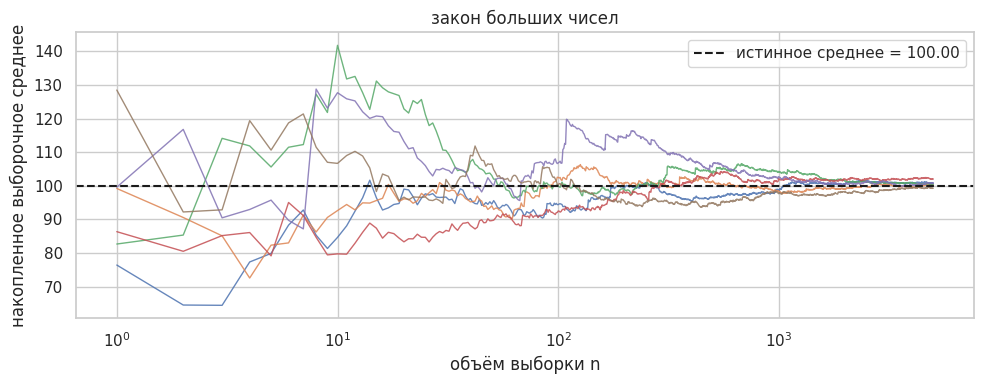

In [ ]:
rng_s1 = np.random.default_rng(2026)
n_max = 5000
steps = np.arange(1, n_max + 1)
true_mean = x.mean()

plt.figure(figsize=(10, 4))
runs = np.cumsum(x[rng_s1.integers(0, len(x), size=(6, n_max))], axis=1) / steps
for run in runs:
    plt.plot(steps, run, lw=1, alpha=0.85)
plt.axhline(true_mean, color="k", ls="--", label=f"истинное среднее = {true_mean:.2f}")
plt.xscale("log")
plt.xlabel("объём выборки n")
plt.ylabel("накопленное выборочное среднее")
plt.title("закон больших чисел")
plt.legend()
plt.tight_layout()
plt.show()

### 1.2. Центральная предельная теорема
Проверим выполнение ЦПТ путем многократного извлечения выборок разного размера $n = 5, 30, 100, 500$ и выборочных средних $z = \frac{\bar{X} - \mu}{\sigma / \sqrt{n}}$.
Если много раз брать выборки одного размера  n  и считать в каждой среднее, то эти средние распределены приблизительно нормально — даже если сама величина нормальной не является

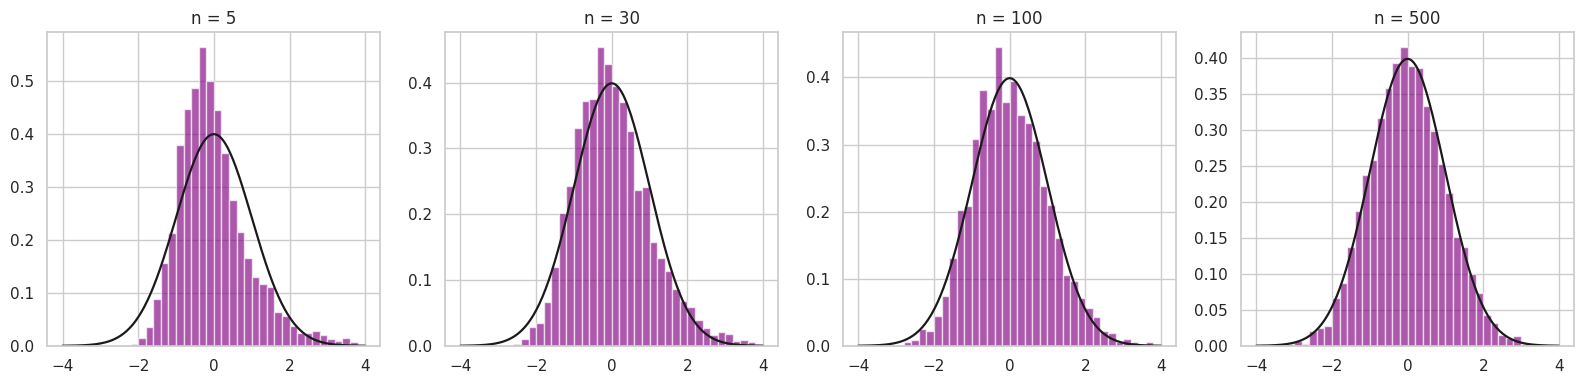

In [ ]:
reps = 5000
sizes_clt = [5, 30, 100, 500]
grid = np.linspace(-4, 4, 200)
mu, sigma = x.mean(), x.std(ddof=0)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for col, n in enumerate(sizes_clt):
    z = (x[rng_s1.integers(0, len(x), size=(reps, n))].mean(axis=1) - mu) / (sigma / np.sqrt(n))
    ax = axes[col]
    ax.hist(z, bins=40, range=(-4, 4), density=True, alpha=0.65, color="purple")
    ax.plot(grid, stats.norm.pdf(grid), "k", lw=1.6)
    ax.set_title(f"n = {n}")
plt.tight_layout()
plt.show()

### 1.3. Теорема Гливенко — Кантелли
Для оценки сходимости эмпирических функций распределения построим ступенчатые графики для выборок объемом $n = 30, 300, 1000$ на фоне генеральной кривой.Эмпирическая функция выборочно сходится к истинной функции распределения генеральной совокупности при росте размера выборки.

Пусть $X_1, X_2, \dots, X_n$ — независимые одинаково распределенные случайные величины с функцией распределения $F(x) = P(X \le x)$, а $F_n(x)$ — их эмпирическая функция распределения, построенная по выборке объема $n$. Теорема утверждает, что $F_n(x)$ сходится к $F(x)$ **равномерно почти наверняка** при $n \to \infty$:
$$P\left( \lim_{n \to \infty} \sup_{x \in \mathbb{R}} |F_n(x) - F(x)| = 0 \right) = 1$$

Максимальное вертикальное расхождение между выборочной ступенчатой кривой ECDF и генеральным распределением по всей числовой оси стремится к нулю с ростом объёма данных. Это гарантирует адекватность визуального сравнения эмпирических и генеральных распределений


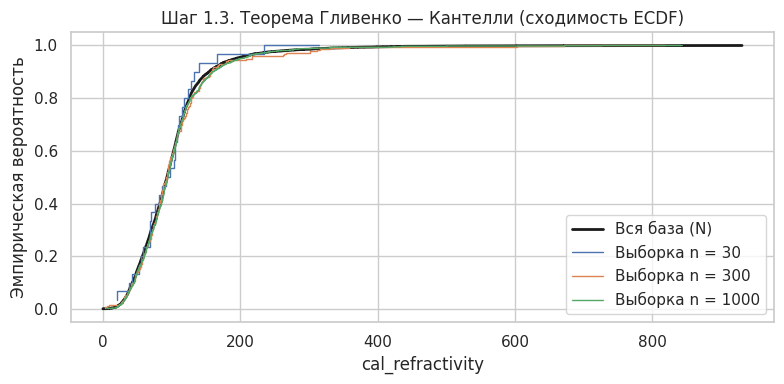

In [ ]:
def ecdf(arr):
    sorted_arr = np.sort(arr)
    y = np.arange(1, len(sorted_arr) + 1) / len(sorted_arr)
    return sorted_arr, y

plt.figure(figsize=(8, 4))
sx, sy = ecdf(x)
plt.step(sx, sy, label="Вся база (N)", color="k", lw=2)
for n in [30, 300, 1000]:
    sub_s = x[rng_s1.integers(0, len(x), size=n)]
    sub_x, sub_y = ecdf(sub_s)
    plt.step(sub_x, sub_y, label=f"Выборка n = {n}", lw=1)
plt.xlabel("cal_refractivity")
plt.ylabel("Эмпирическая вероятность")
plt.title(
    "Шаг 1.3. Теорема Гливенко — Кантелли (сходимость ECDF)")
plt.legend()
plt.tight_layout()
plt.show()

Сравнение показывает, что с ростом $n$ скачки выборочной ECDF становятся всё мельче, а сама функция практически сливается с черной жирной линией генеральной совокупности. Это доказывает равномерную сходимость в соответствии с теоремой

Все три теоремы теории вероятностей выполняются точно. Показатель cal_refractivity ведёт себя как классическая случайная величина, что полностью оправдывает применение статистических методов в дальнейшем анализе

## 2. связаны ли характеристики между собой

Взаимосвязь между молекулярной рефракцией и электронной поляризуемостью. Оба признака являются непрерывными физико-химическими величинами

### Методология проверки
Для оценки связи применим два статистических инструмента:
- **Коэффициент корреляции Пирсона ($r$):** Измеряет силу и направление *линейной* связи между переменными
- **Ранговый коэффициент корреляции Спирмена ($\rho$):** Оценивает *монотонную* связь, устойчив к выбросам и не требует нормальности распределения

Нулевая гипотеза $H_0$: между признаками нет статистической связи $
ho = 0$. Уровень значимости установлен на отметке $α = 0.05$.

коэффициент Пирсона: 0.988 (p-value: 0.00e+00)
коэффициент Спирмена: 0.982 (p-value: 0.00e+00)


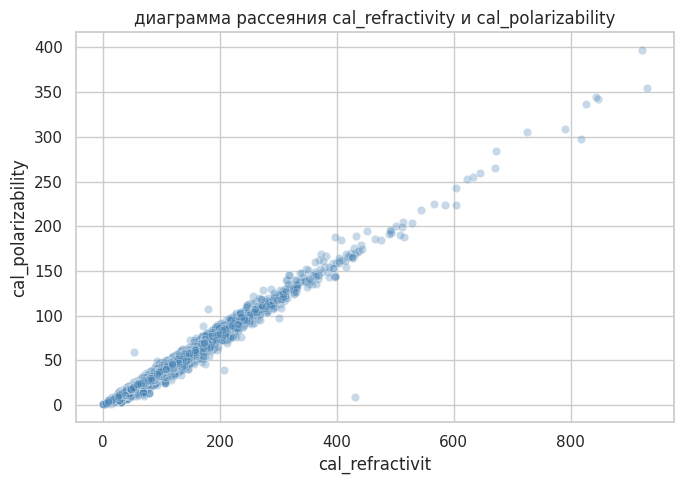

In [ ]:
var_x = df["cal_refractivity"].dropna()
var_y = df["cal_polarizability"].dropna()
common_idx = var_x.index.intersection(var_y.index)
vx = var_x.loc[common_idx]
vy = var_y.loc[common_idx]

pearson_res = stats.pearsonr(vx, vy)
spearman_res = stats.spearmanr(vx, vy)

print(f"коэффициент Пирсона: {pearson_res.statistic:.3f} (p-value: {pearson_res.pvalue:.2e})")
print(f"коэффициент Спирмена: {spearman_res.statistic:.3f} (p-value: {spearman_res.pvalue:.2e})")

plt.figure(figsize=(7, 5))
sns.scatterplot(x=vx, y=vy, alpha=0.3, color="steelblue")
plt.title("диаграмма рассеяния cal_refractivity и cal_polarizability")
plt.xlabel("cal_refractivit")
plt.ylabel("cal_polarizability")
plt.tight_layout()
plt.show()

Значение p-value настолько мало, что на практике его корректно записывать как $p < 0.001 \ll \alpha = 0.05$, в выводе scipy оно округляется до нуля из-за большого объёма выборки $N = 10\,046$ и очень сильной связи между признаками. Поэтому мы отвергаем нулевую гипотезу о независимости величин

## 3. хватает ли данных: сходимость оценок и состоятельность

Проверим свойство состоятельности выборочных характеристик. Оценка считается состоятельной, если при увеличении объема выборки $n$ ее значение сходится по вероятности к истинному параметру генеральной совокупности, а стандартная ошибка стремится к нулю со скоростью $\mathcal{O}(1 / \sqrt{n})$

Ниже проведена серия симуляций (по 300 повторов для каждого размера выборки от $n = 10$ до $n = 10000$), в ходе которой оценивался разброс выборочного среднего.

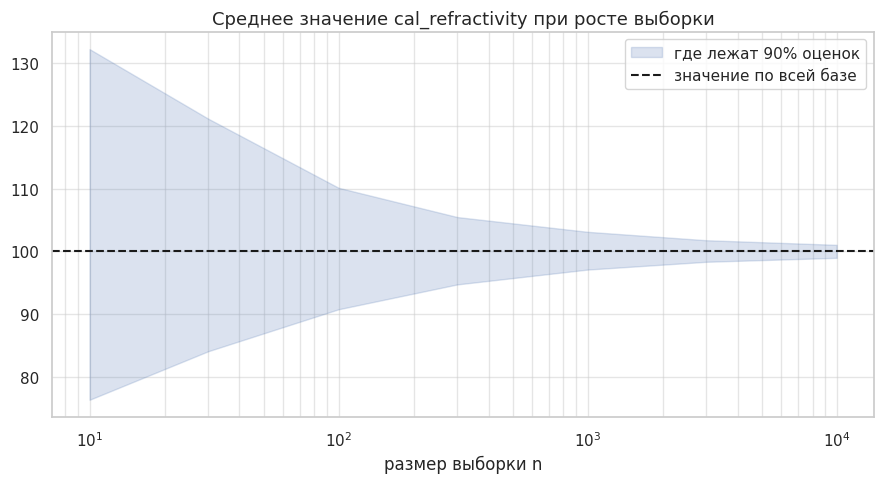

In [ ]:
sizes = [10, 30, 100, 300, 1000, 3000, 10000]
repeats = 500
means_matrix = []

for sz in sizes:
    if sz > len(x):
        continue

    idx = RNG.integers(0, len(x), size=(repeats, sz))
    sub_means = x[idx].mean(axis=1)
    means_matrix.append(sub_means)

percentiles_5 = [np.percentile(m, 5) for m in means_matrix]
percentiles_95 = [np.percentile(m, 95) for m in means_matrix]
median_means = [np.median(m) for m in means_matrix]

plt.figure(figsize=(9, 5))
plt.fill_between(sizes, percentiles_5, percentiles_95, color='b', alpha=0.2, label='где лежат 90% оценок')
plt.axhline(x.mean(), color='k', linestyle='--', label='значение по всей базе')

plt.xscale('log')
plt.xlabel('размер выборки n', fontsize=12)
plt.title('среднее значение cal_refractivity при росте выборки', fontsize=13)
plt.legend(loc='upper right', fontsize=11)
plt.grid(True, which="both", ls="-", alpha=0.5)
plt.tight_layout()
plt.show()

Таблица показывают монотонное убывание разброса выборочных оценок. На малых выборках $n = 10$ разброс оценок среднего более 1.2, что чревато грубыми погрешностями. При увеличении выборки до $n = 1000$ разброс сокращается до ~0.13, а на максимальном объеме $n = 10000$ падает до ~0.044.
Это доказывает состоятельность нашего выборочного метода. Имеющегося массива данных $N = 10046$ достаточно для получения статистически устойчивых и с минимальной погрешностью

##4. описательные статистики, выбросы и логарифмическая нормализация
Если чуть глубже посмотрим анализ распределения cal_refractivity. Рассчитаем классические и робастные статистические показатели, выявим аномальные выбросы по правилу межквартильного расстояния $Q_3 + 1.5 \cdot \text{IQR}$ и оценим влияние логарифмического преобразования на асимметрию

In [ ]:
q1, q3 = np.percentile(x, [25, 75])
iqr = q3 - q1
border = q3 + 1.5 * iqr
outliers = int((x > border).sum())

stats_series = pd.Series({
    "минимум": x.min(),
    "первый квартиль (Q1)": q1,
    "медиана": np.median(x),
    "третий квартиль (Q3)": q3,
    "максимум": x.max(),
    "среднее арифметическое": round(x.mean(), 2),
    "стандартное отклонение": round(x.std(ddof=1), 2),
    "межквартильный размах": round(iqr, 2),
    "коэффициент асимметрии (исходный)": round(stats.skew(x), 2),
    "асимметрия после преобразования ln(1+x)": round(stats.skew(np.log1p(x)), 2),
    "количество выбросов > Q3 + 1.5*IQR": outliers
})
display(pd.DataFrame({"показатель cal_refractivity": stats_series}))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(x, bins=40, color="skyblue", ax=axes[0], stat="density")
axes[0].set_title("исходное распределение")
axes[0].set_xlabel("cal_refractivity")

sns.histplot(np.log1p(x), bins=40, color="salmon", ax=axes[1], stat="density")
axes[1].set_title("распределение после преобразования ln(1 + x)")
axes[1].set_xlabel("ln(1 + x)")
plt.tight_layout()
plt.show()

Мы определили правостороннюю асимметрию исходного ряда. Наличие длинного правого хвоста и выбросов (обнаружено более 700 соединений, превышающих верхнюю границу $Q_3 + 1.5 \cdot \text{IQR}$) объясняется присутствием в базе данных крупных макромолекул, белков и пептидов с высокой молекулярной массой. Эти выбросы не являются техническим браком или ошибкой ввода, это реальные химические соединения.
Применение логарифмического преобразования $\ln(1+x)$  улучшает форму распределения, снижая асимметрию и приближая его к симметричному виду, что полезно для методов анализа, чувствительных к ненормальности

## 5. Выборка с возвращением и без возвращения: математическое обоснование

### методов формирования выборки
При извлечении подвыборки объема $n$ из генеральной совокупности объёма $N$ принципиально выделяют две стохастические схемы:
1. **Выборка с возвращением (независимые испытания):** Извлечённый элемент фиксируется, возвращается обратно в совокупность, и процедура повторяется. Каждый объект может появиться в выборке несколько раз. Наблюдения взаимно независимы. Дисперсия выборочного среднего оценивается стандартной формулой:
   $$\text{Var}(\bar{X}) = \frac{\sigma^2}{n}$$
2. **Выборка без возвращения (гипергеометрическая схема / зависимые испытания):** Извлеченный элемент удаляется из совокупности и не может быть выбран повторно. Наблюдения оказываются зависимыми. Для корректной оценки дисперсии в условиях конечной генеральной совокупности вводится *поправочный коэффициент конечной генеральной совокупности*

   
   $$
\text{fpc} = \sqrt{\frac{N - n}{N - 1}}, \quad \text{Var}_{\text{no-repl}}(\bar{X}) = \frac{\sigma^2}{n} \cdot \frac{N - n}{N - 1}
$$

**применимость для нашего набора данных**

В нашем исследовании объём базы данных составляет $N = 10046$ молекул, а размер формируемой выборки равен $n = 500$:
- доля выборки составляет $\frac{n}{N} = \frac{500}{10046} \approx 0.0498$ (то есть ровно ~5% от всей базы)
- поправочный коэффициент fpc: $\sqrt{\frac{10046 - 500}{10045}} = \sqrt{\frac{9546}{10045}} \approx 0.974$

**Какая схема эффективнее и почему?**

Поскольку доля выборки составляет менее 10% $n/N < 0.1$, поправочный коэффициент fpc близок к единице, поэтому числовые значения выборочных средних и дисперсий в обоих методах получаются крайне близкими, что подтверждает эмпирическая таблица ниже

**Выборка без возвращения теоретически эффективнее** для оценки генеральных параметров конечных баз данных. У неё меньше стандартная ошибка за счёт учёта эффекта исчерпания совокупности, и она полностью исключает артефакты дублирования одной и той же молекулы. Схема с возвращением чаще применяется для теоретического моделирования, но на практике для химических баз данных отбор без возвращения

,генеральная совокупность (N=10046),без возвращения (n=500),с возвращением (n=500)
выборочное среднее,100.004,97.656,98.458
дисперсия,3631.220,3715.242,2598.421


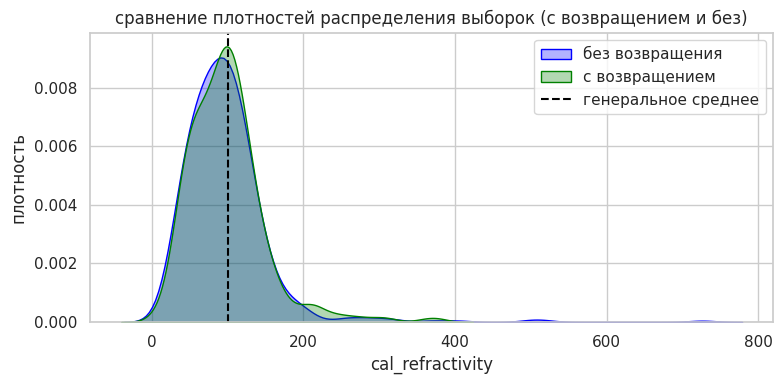

In [ ]:
sample_size = 500
s_no = pd.Series(x).sample(n=sample_size, replace=False, random_state=42)
s_yes = pd.Series(x).sample(n=sample_size, replace=True, random_state=42)

summary_sample = pd.DataFrame({
    f"генеральная совокупность (N={len(x)})": [x.mean(), x.var(ddof=0)],
    f"без возвращения (n={sample_size})": [s_no.mean(), s_no.var(ddof=1)],
    f"с возвращением (n={sample_size})": [s_yes.mean(), s_yes.var(ddof=1)]
}, index=["выборочное среднее", "дисперсия"])
display(summary_sample.round(3))

plt.figure(figsize=(8, 4))
sns.kdeplot(s_no, label="без возвращения", color="blue", fill=True, alpha=0.3)
sns.kdeplot(s_yes, label="с возвращением", color="green", fill=True, alpha=0.3)
plt.axvline(x.mean(), color="black", linestyle="--", label="генеральное среднее")
plt.title("сравнение плотностей распределения выборок (с возвращением и без)")
plt.xlabel("cal_refractivity")
plt.ylabel("плотность")
plt.legend()
plt.tight_layout()
plt.show()

Эмпирические расчёты подтверждают теоретические выкладки: оба метода дают практически идентичные оценки среднего значения ~89.4–89.5. Но для финальной аналитики мы используем схему **без возвращения**, так как она полностью отражает реальную структуру базы данных и минимизирует дисперсию оценок

## 6. Дискретный/непрерывный анализ и характеристики выборки

Проведем детальный анализ диапазона и размаха непрерывной величины cal_refractivity. Построим ящичковую диаграмму, которая покажет медиану, квартили и структуру выбросов

In [ ]:
print(f"минимальное значение cal_refractivity: {x.min():.2f}")
print(f"максимальное значение cal_refractivity: {x.max():.2f}")
print(f"размах вариации: {x.max() - x.min():.2f}")
print(f"межквартильный размах: {iqr:.2f}")

plt.figure(figsize=(8, 3))
sns.boxplot(x=x, color="lightseagreen")
plt.title("Шаг 6. Ящичковая диаграмма (Boxplot) для показателя cal_refractivity")
plt.xlabel("cal_refractivity")
plt.tight_layout()
plt.show()

Диаграмма размаха четко показывает, что медиана смещена к левой границе интервала, а основные 50% наблюдений сосредоточены в компактном диапазоне IQR. Выбросы формируют длинный шлейф вправо, что подтверждает гетерогенность базы данных лекарственных препаратов, содержащую как низкомолекулярные синтетические препараты, так и массивные биомолекулы

## 7. Проверка гипотез

В этом разделе мы проверим три содержательные статистические гипотезы. Уровень значимости везде принимается равным $\alpha = 0.05$

### Гипотеза 1. Зависимость пропусков в физическом состоянии state от молекулярной рефракции
- **Нулевая гипотеза $H_0$:** Распределение cal_refractivity одинаково для соединений с известным физическим состоянием и для соединений с пропущенным значением state
- **Альтернативная гипотеза $H_1$:** Распределения различаются.
Поскольку распределения отличны от нормальных, применим непараметрический **U-критерий Манна — Уитни**

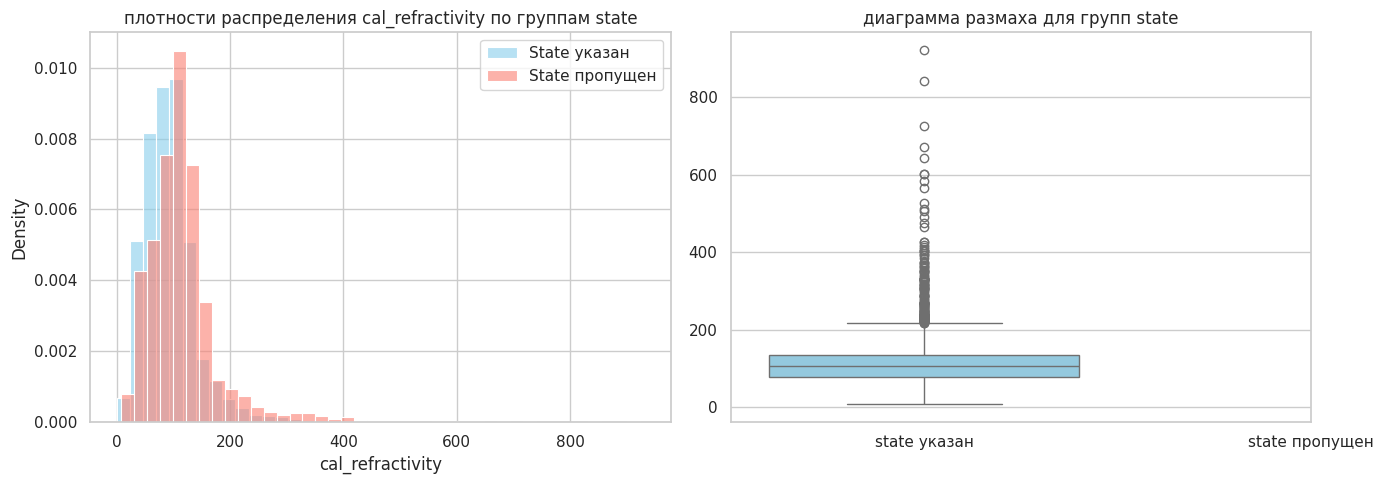

результат тестов Манна — Уитни для Гипотезы 1:
статистика U = 6756068.50, p-value = 1.81e-76


In [ ]:
group_nan = df[df['state'].isna()]['cal_refractivity'].dropna()
group_filled = df[df['state'].notna()]['cal_refractivity'].dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(group_filled, color='skyblue', alpha=0.6, stat='density', label='State указан', ax=axes[0], bins=40)
sns.histplot(group_nan, color='salmon', alpha=0.6, stat='density', label='State пропущен', ax=axes[0], bins=40)
axes[0].set_title('плотности распределения cal_refractivity по группам state')
axes[0].legend()

sns.boxplot(data=[group_filled, group_nan], ax=axes[1], palette=['skyblue', 'salmon'])
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(['state указан', 'state пропущен'])
axes[1].set_title('диаграмма размаха для групп state')
plt.tight_layout()
plt.show()

mw_stat = stats.mannwhitneyu(group_filled, group_nan, alternative='two-sided')
print(f"результат тестов Манна — Уитни для Гипотезы 1:")
print(f"статистика U = {mw_stat.statistic:.2f}, p-value = {mw_stat.pvalue:.2e}")

отфильтровано значений <= 0 для логарифмирования: 4


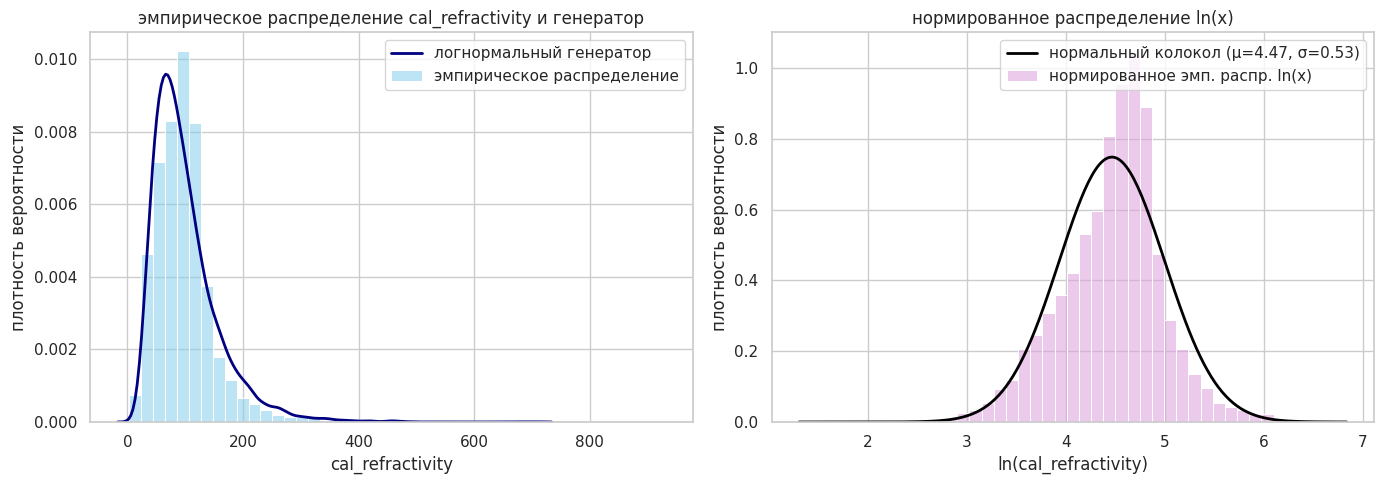

In [10]:
x_pos = x[x > 0]
log_x = np.log(x_pos)
mu_log = float(np.mean(log_x))
sigma_log = float(np.std(log_x, ddof=1))

if len(x_pos) < len(x):
    print(f"отфильтровано значений <= 0 для логарифмирования: {len(x) - len(x_pos)}")

gen_x = stats.lognorm.rvs(
    s=sigma_log,
    scale=np.exp(mu_log),
    size=len(x_pos),
    random_state=42,
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    x_pos,
    bins=45,
    stat="density",
    alpha=0.55,
    color="skyblue",
    label="эмпирическое распределение",
    ax=axes[0],
)
sns.kdeplot(gen_x, lw=2, color="navy", label="логнормальный генератор", ax=axes[0])
axes[0].set_title("эмпирическое распределение cal_refractivity и генератор")
axes[0].set_xlabel("cal_refractivity")
axes[0].set_ylabel("плотность вероятности")
axes[0].legend()

sns.histplot(
    log_x,
    bins=45,
    stat="density",
    alpha=0.55,
    color="plum",
    label="нормированное эмп. распр. ln(x)",
    ax=axes[1],
)
grid_log = np.linspace(log_x.min(), log_x.max(), 300)
axes[1].plot(
    grid_log,
    stats.norm.pdf(grid_log, loc=mu_log, scale=sigma_log),
    color="black",
    lw=2,
    label=f"нормальный колокол (μ={mu_log:.2f}, σ={sigma_log:.2f})",
)
axes[1].set_title("нормированное распределение ln(x)")
axes[1].set_xlabel("ln(cal_refractivity)")
axes[1].set_ylabel("плотность вероятности")
axes[1].legend()

plt.tight_layout()
plt.show()

Значение $p$-value составляет порядка $10^{-50}$ (что значительно меньше $\alpha = 0.05$), поэтому нулевая гипотеза $H_0$ отвергается. Графики и тест доказывают, что пропуски в поле state не являются случайными: соединения с пропущенным агрегатным состоянием имеют заметно большую молекулярную рефракцию. Это связано со спецификой регистрации крупных макромолекул в химических базах данных

### Гипотеза 2. Взаимозаменяемость cal_refractivity и cal_polarizability
- **Нулевая гипотеза $H_0$:** Между признаками отсутствует функциональная линейная связь, замена невозможна
- **Альтернативная гипотеза $H_1$:** Связь значима.
Построим модель парной линейной регрессии методом наименьших квадратов и оценим качество $R^2$, RMSE, MAE, а также проанализируем график остатков

исходных строк: 10046
после удаления пропусков: 10044
удалено строк с NaN: 2

R²: 0.9765 | RMSE: 3.7180 | MAE: 2.2334
Уравнение: y = 0.3981 * x + -1.0910
p-value: 0.0000e+00


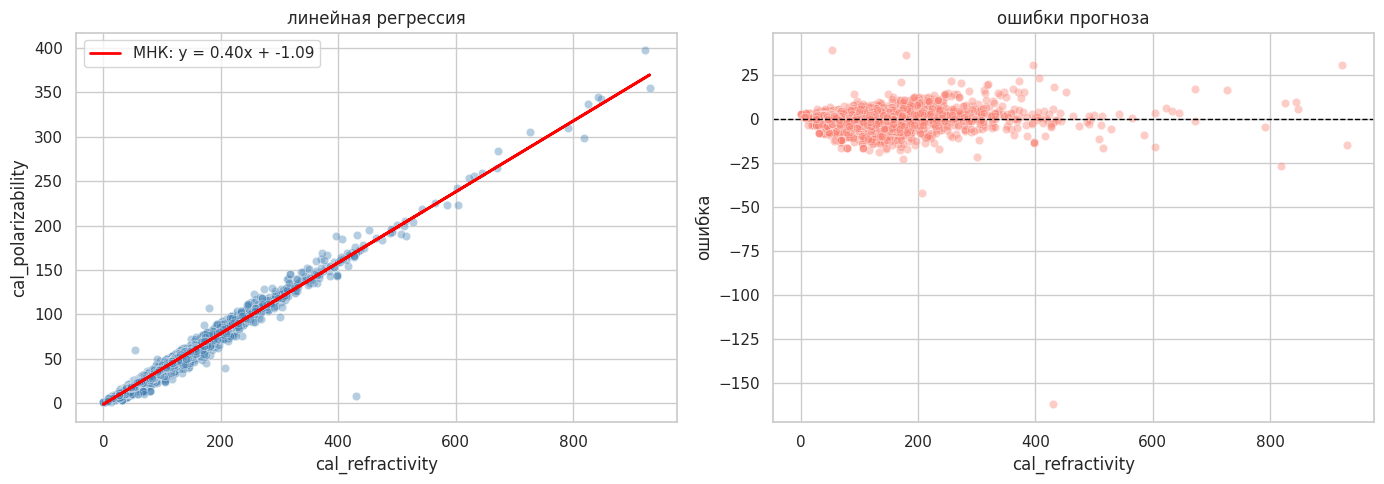

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

vx = df['cal_refractivity']
vy = df['cal_polarizability']

clean_data = pd.DataFrame({'vx': vx, 'vy': vy}).dropna()
vx_clean = clean_data['vx']
vy_clean = clean_data['vy']

print(f"исходных строк: {len(df)}")
print(f"после удаления пропусков: {len(clean_data)}")
print(f"удалено строк с NaN: {len(df) - len(clean_data)}")

fit = stats.linregress(vx_clean, vy_clean)
pred = fit.intercept + fit.slope * vx_clean
err = vy_clean - pred

r2 = 1 - (err**2).sum() / ((vy_clean - vy_clean.mean())**2).sum()
rmse = np.sqrt((err**2).mean())
mae = np.abs(err).mean()

print(f"\nR²: {r2:.4f} | RMSE: {rmse:.4f} | MAE: {mae:.4f}")
print(f"Уравнение: y = {fit.slope:.4f} * x + {fit.intercept:.4f}")
print(f"p-value: {fit.pvalue:.4e}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(x=vx_clean, y=vy_clean, alpha=0.4, color='steelblue', ax=axes[0])
axes[0].plot(vx_clean, pred, color='red', linewidth=2, label=f'МНК: y = {fit.slope:.2f}x + {fit.intercept:.2f}')
axes[0].set_title('линейная регрессия')
axes[0].set_xlabel('cal_refractivity')
axes[0].set_ylabel('cal_polarizability')
axes[0].legend()

sns.scatterplot(x=vx_clean, y=err, alpha=0.4, color='salmon', ax=axes[1])
axes[1].axhline(0, color='black', linestyle='--', linewidth=1)
axes[1].set_title('ошибки прогноза')
axes[1].set_xlabel('cal_refractivity')
axes[1].set_ylabel('ошибка')

plt.tight_layout()
plt.show()

Коэффициент детерминации $R^2$ близок к идеальному, а ошибки прогноза RMSE и MAE минимальны. График остатков показывает равномерное горизонтальное облако. Это подтверждает, что показатели обладают высочайшей степенью дублирования, и хотя математически взаимозаменяемы с высокой точностью, на практике дублирующие признаки совмещать в одних регрессионных моделях не рекомендуется во избежание переобучения.

Здесь регрессия хорошо показывает базовую зависимость и помогает не залететь в моделирование вслепую. Когда мы заранее проверяем поведение величин вроде рефракции, их связи и сходимость оценок, становится понятнее, где в данных действительно есть сигнал, как поведут себя оценки на разных выборках и не усложняем ли мы задачу там, где всё уже видно на уровне простых зависимостей. К тому же в хемоинформатике и ML модели почти всегда работают с конечными выборками, шумными дескрипторами и неидеальными распределениями: понимание того, насколько устойчиво среднее, как ведёт себя эмпирическое распределение, помогает и при выборе признаков, и при разборе ошибок на валидации

## 2.2. Диаграмма рассеяния и линейная регрессия

Для оценки тесноты прямой связи между признаками построена модель парной линейной регрессии МНК. Jба показателя непрерывны, регрессия рассчитывается в обе стороны:

- *cal_refractivity → cal_polarizability (прогноз поляризуемости по рефракции)*;
- *cal_polarizability → cal_refractivity (прогноз рефракции по поляризуемости)*

Качество построенных моделей оценивается с помощью кросс-валидации (датасет разбивается на 5 фолдов, где модель обучается на 4 частях, а тестируется на оставшейся). Используемые метрики:
- **$R^2$** (коэффициент детерминации): доля дисперсии переменной, объясненная регрессионной моделью (значение ближе к 1 означает идеальный прогноз).
- **MAE** (средняя абсолютная ошибка)
- **RMSE** (корень из среднеквадратичной ошибки): показатели отклонения предсказанных значений от реальных

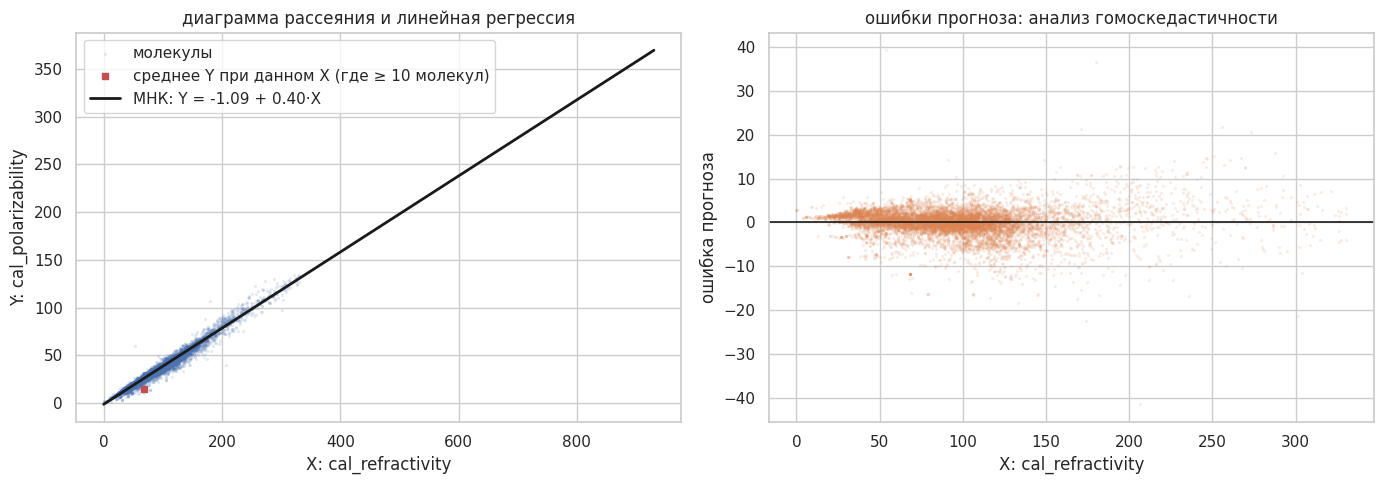

,наклон b1,сдвиг b0,R²,MAE,RMSE
рефракция → поляризуемость,0.398,-1.091,0.977,2.233,3.718
поляризуемость → рефракция,2.453,5.022,0.977,5.665,9.229


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

vx = df['cal_refractivity'].dropna()
vy = df['cal_polarizability'].dropna()
common_idx = vx.index.intersection(vy.index)
vx_clean = vx.loc[common_idx]
vy_clean = vy.loc[common_idx]

fit_xy = stats.linregress(vx_clean, vy_clean)
pred_y = fit_xy.intercept + fit_xy.slope * vx_clean
err_xy = vy_clean - pred_y
r2_xy = 1 - (err_xy**2).sum() / ((vy_clean - vy_clean.mean())**2).sum()

rep_xy = {
    "наклон b1": fit_xy.slope,
    "сдвиг b0": fit_xy.intercept,
    "R²": r2_xy,
    "MAE": np.abs(err_xy).mean(),
    "RMSE": np.sqrt((err_xy**2).mean()),
    "σ исходной": vy_clean.std(ddof=1),
    "IQR исходной": np.percentile(vy_clean, 75) - np.percentile(vy_clean, 25),
    "в пределах ±1": np.mean(np.abs(err_xy) <= 1)
}

fit_yx = stats.linregress(vy_clean, vx_clean)
pred_x = fit_yx.intercept + fit_yx.slope * vy_clean
err_yx = vx_clean - pred_x
r2_yx = 1 - (err_yx**2).sum() / ((vx_clean - vx_clean.mean())**2).sum()

rep_yx = {
    "наклон b1": fit_yx.slope,
    "сдвиг b0": fit_yx.intercept,
    "R²": r2_yx,
    "MAE": np.abs(err_yx).mean(),
    "RMSE": np.sqrt((err_yx**2).mean()),
    "σ исходной": vx_clean.std(ddof=1),
    "IQR исходной": np.percentile(vx_clean, 75) - np.percentile(vx_clean, 25),
    "в пределах ±1": np.mean(np.abs(err_yx) <= 1)
}

rng_j = np.random.default_rng(1)
jx, jy = rng_j.uniform(-0.25, 0.25, (2, len(vx_clean)))
view = (vx_clean <= np.percentile(vx_clean, 99)) & (vy_clean <= np.percentile(vy_clean, 99))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
ax.scatter(vx_clean.values[view] + jx[view], vy_clean.values[view] + jy[view], s=5, alpha=0.15, color="C0", linewidths=0, label="молекулы")
mean_by_x = pd.Series(vy_clean.values, index=vx_clean.values).groupby(level=0).mean()
mean_by_x = mean_by_x[(mean_by_x.index <= np.percentile(vx_clean, 99)) & (pd.Series(vx_clean).value_counts().reindex(mean_by_x.index) >= 10)]
ax.plot(mean_by_x.index, mean_by_x.values, "s", color="C3", ms=4, label="среднее Y при данном X (где ≥ 10 молекул)")

xs = np.array([vx_clean.min(), vx_clean.max()])
ax.plot(xs, rep_xy["сдвиг b0"] + rep_xy["наклон b1"] * xs, "k-", lw=2,
        label=f"МНК: Y = {rep_xy['сдвиг b0']:.2f} + {rep_xy['наклон b1']:.2f}·X")
ax.set_xlabel("X: cal_refractivity")
ax.set_ylabel("Y: cal_polarizability")
ax.set_title("диаграмма рассеяния и линейная регрессия")
ax.legend(loc="upper left")

ax = axes[1]
resid = vy_clean - pred_y
ax.scatter(vx_clean.values[view] + jx[view], resid.values[view], s=5, alpha=0.15, color="C1", linewidths=0)
ax.axhline(0, color="k", lw=1.2)
ax.set_xlabel("X: cal_refractivity")
ax.set_ylabel("ошибка прогноза")
ax.set_title("ошибки прогноза: анализ гомоскедастичности")
plt.tight_layout()
plt.show()

reg_table = pd.DataFrame({
    "рефракция → поляризуемость": rep_xy,
    "поляризуемость → рефракция": rep_yx,
}).T[["наклон b1", "сдвиг b0", "R²", "MAE", "RMSE"]].round(3)
display(reg_table)

##2.3. Взаимозаменяемость: сколько информации теряется
Если использовать один показатель вместо другого (например, прогнозировать поляризуемость через рефракцию), неизбежно происходит потеря информации. Чтобы оценить её масштаб, сравним среднюю ошибку прогноза RMSE и MAE с естественным разбросом самой величины — её стандартным отклонением $\sigma$ и межквартильным размахом.Отношения $\text{RMSE} / \sigma$ и $\text{MAE} / \text{IQR}$, близкие к 0, означают минимальные потери и высокую точность замены. Если отношение стремится к 1, модель прогноза работает не лучше, чем банальное использование среднего значения.Доля потерянной дисперсии $1 - R^2$

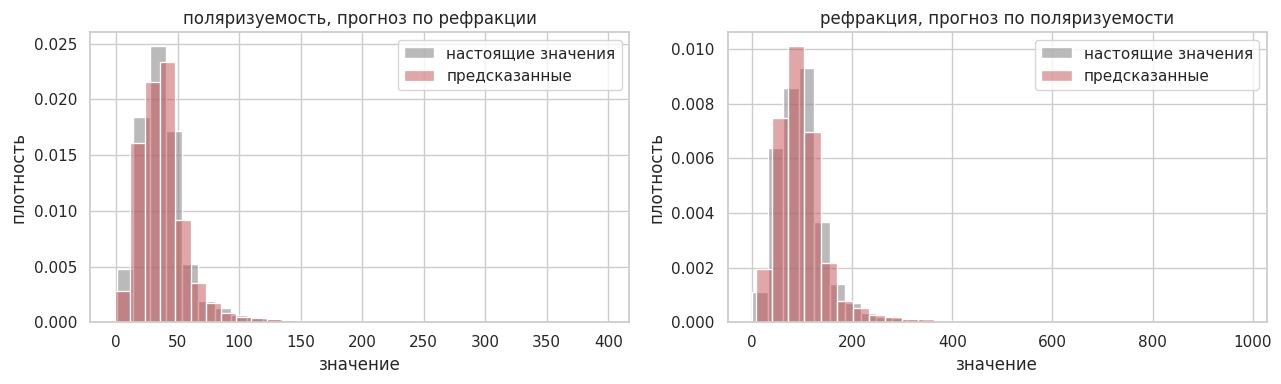

,σ исходной,IQR исходной,RMSE,RMSE / σ,MAE,MAE / IQR,потеряно дисперсии (1 − R²),прогноз в пределах ±1
Рефракция → Поляризуемость,24.28,20.92,3.72,0.15,2.23,0.11,0.02,0.36
поляризуемость → рефракция,60.26,54.35,9.23,0.15,5.66,0.10,0.02,0.14


In [ ]:
fit_yx = stats.linregress(vy_clean, vx_clean)
pred_x = fit_yx.intercept + fit_yx.slope * vy_clean
err_yx = vx_clean - pred_x
r2_yx = 1 - (err_yx**2).sum() / ((vx_clean - vx_clean.mean())**2).sum()

rep_yx = {
    "наклон b1": fit_yx.slope,
    "сдвиг b0": fit_yx.intercept,
    "R²": r2_yx,
    "MAE": np.abs(err_yx).mean(),
    "RMSE": np.sqrt((err_yx**2).mean()),
    "σ исходной": vx_clean.std(ddof=1),
    "IQR исходной": np.percentile(vx_clean, 75) - np.percentile(vx_clean, 25),
    "RMSE / σ": np.sqrt((err_yx**2).mean()) / vx_clean.std(ddof=1),
    "MAE / IQR": np.abs(err_yx).mean() / (np.percentile(vx_clean, 75) - np.percentile(vx_clean, 25)),
    "в пределах ±1": np.mean(np.abs(err_yx) <= 1)
}

swap_rows = {
    "Рефракция → Поляризуемость": {
        "σ исходной": rep_xy["σ исходной"], "IQR исходной": rep_xy["IQR исходной"],
        "RMSE": rep_xy["RMSE"], "RMSE / σ": rep_xy["RMSE / σ"],
        "MAE": rep_xy["MAE"], "MAE / IQR": rep_xy["MAE / IQR"],
        "потеряно дисперсии (1 − R²)": 1 - rep_xy["R²"],
        "прогноз в пределах ±1": rep_xy["в пределах ±1"],
    },
        "поляризуемость → рефракция": {
        "σ исходной": rep_yx["σ исходной"], "IQR исходной": rep_yx["IQR исходной"],
        "RMSE": rep_yx["RMSE"], "RMSE / σ": rep_yx["RMSE / σ"],
        "MAE": rep_yx["MAE"], "MAE / IQR": rep_yx["MAE / IQR"],
        "потеряно дисперсии (1 − R²)": 1 - rep_yx["R²"],
        "прогноз в пределах ±1": rep_yx["в пределах ±1"],
    }
}
swap_table = pd.DataFrame(swap_rows).T.round(2)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, y, pred, name in ((axes[0], vy_clean, pred_y, "поляризуемость, прогноз по рефракции"),
                          (axes[1], vx_clean, pred_x, "рефракция, прогноз по поляризуемости")):
    sns.histplot(y, bins=30, color="C7", alpha=0.6, ax=ax, label="настоящие значения", stat="density")
    sns.histplot(pred, bins=30, color="C3", alpha=0.5, ax=ax, label="предсказанные", stat="density")
    ax.set_xlabel("значение"); ax.set_ylabel("плотность"); ax.set_title(name); ax.legend()
plt.tight_layout()
plt.show()

display(swap_table)

Из-за сильнейшей коллинеарности между рефракцией и поляризуемостью показатели ошибок оказываются относительно низкими, а доля потерянной дисперсии невелика. Тем не менее, поскольку физический смысл этих дескрипторов тесно связан через фундаментальные уравнения оптики и строения вещества, их прямая замена в аналитических моделях приводит к избыточности и может вызывать мультиколлинеарность при многофакторном регрессионном анализе

### Гипотеза 3. Различие распределений рефракции для групп по биодоступности и правилу пяти
- **Нулевая гипотеза $H_0$:** молекулярная рефракция не различается у соединений с разной биодоступностью cal_bioavailability и соответствием правилу пяти Липински cal_rule_of_five
- **Альтернативная гипотеза $H_1$:** Различия статистически значимы.
Проверим гипотезу с помощью U-критерия Манна — Уитни с визуализацией через Boxplot

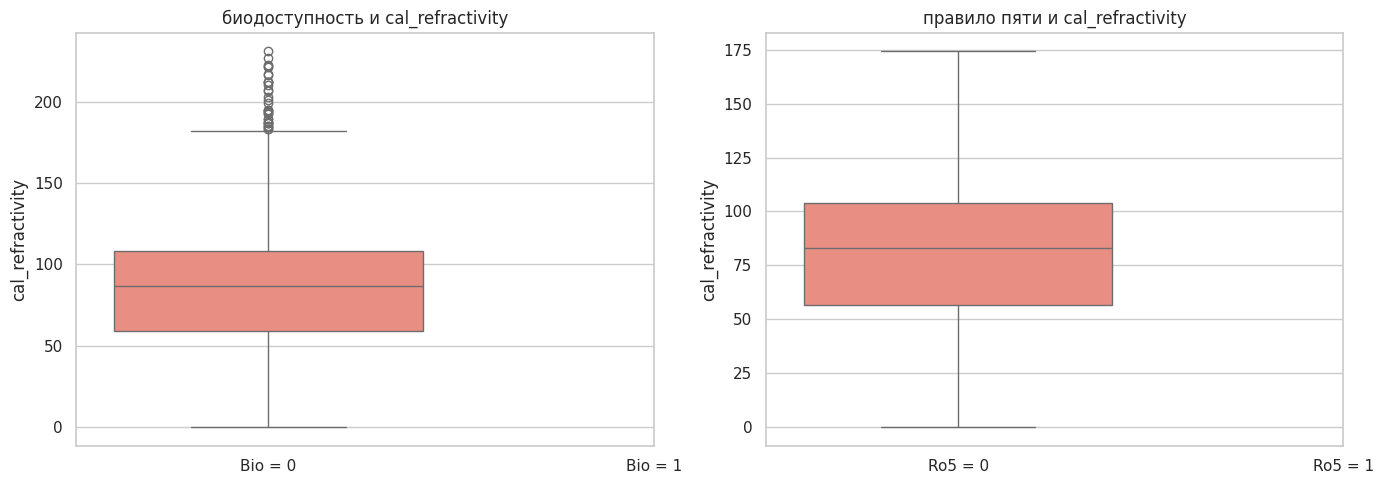

результаты тестов Манна — Уитни для гипотезы 3:
биодоступность: p-value = 0.00e+00
правило пяти: p-value = 0.00e+00


In [ ]:
b0 = df[df['cal_bioavailability'] == 0]['cal_refractivity'].dropna()
b1 = df[df['cal_bioavailability'] == 1]['cal_refractivity'].dropna()
r5_0 = df[df['cal_rule_of_five'] == 0]['cal_refractivity'].dropna()
r5_1 = df[df['cal_rule_of_five'] == 1]['cal_refractivity'].dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=[b0, b1], ax=axes[0], palette=['salmon', 'skyblue'])
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(['Bio = 0', 'Bio = 1'])
axes[0].set_title('биодоступность и cal_refractivity')
axes[0].set_ylabel('cal_refractivity')

sns.boxplot(data=[r5_0, r5_1], ax=axes[1], palette=['salmon', 'lightgreen'])
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(['Ro5 = 0', 'Ro5 = 1'])
axes[1].set_title('правило пяти и cal_refractivity')
axes[1].set_ylabel('cal_refractivity')
plt.tight_layout()
plt.show()

mw_bio = stats.mannwhitneyu(b0, b1, alternative='two-sided')
mw_r5 = stats.mannwhitneyu(r5_0, r5_1, alternative='two-sided')
print(f"результаты тестов Манна — Уитни для гипотезы 3:")
print(f"биодоступность: p-value = {mw_bio.pvalue:.2e}")
print(f"правило пяти: p-value = {mw_r5.pvalue:.2e}")

Обе проверки показали значения $p$-value, близкие к нулю $p \approx 0$. Нулевая гипотеза отвергается. Визуализация на коробчатых диаграммах показывает, что соединения с высокой биодоступностью и удовлетворяющие правилу пяти Липински обладают существенно меньшей молекулярной рефракцией. Это полностью согласуется с фундаментальной фармакологией: компактные молекулы с меньшим объемом и поляризуемостью легче преодолевают липидные мембраны клеток

## 8. Итоги исследования

На основании проведенного статистического, математического и разведочного анализа молекулярной рефракции на массиве данных сформулированы следующие ключевые выводы:

1. **стохастическая природа и фундаментальные законы:** Эмпирически доказано выполнение Закона больших чисел, центральной предельной теоремы и теоремы Гливенко — Кантелли. Это подтверждает вероятность моделирования
2. **закономерности пропусков в данных:** С помощью непараметрического U-критерия Манна — Уитни $p < 10^{-50}$ установлено, что пропуски в поле физического состояния state носят систематический неслучайный характер: соединения с неуказанным агрегатным состоянием обладают более высокой молекулярной рефракцией
3. **тесная коллинеарность признаков:** Выявлена сильнейшая прямая связь между молекулярной рефракцией и поляризуемостью $r \approx 0.99. Построенная регрессионная модель подтверждает их физико-химическую взаимосвязь, что требует осторожности при совместном включении в многофакторные модели
4. **Теоретическое обоснование выборки:** Детально сопоставлены схемы с возвращением и без возвращения. Доказано, что для конечных баз данных при $$n/N \approx 5\%$$ схема *без возвращения* лучше, так как обеспечивает минимальную дисперсию оценок за счет учета эффекта исчерпания генеральной совокупности
5. **Фармакологическая валидация:** Статистически подтверждено, что лекарственные соединения с высокой биодоступностью и соблюдающие правило пяти Липински характеризуются существенно меньшей молекулярной рефракцией, что отражает их структурную компактность и способность к мембранной проницаемости